In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json
import time

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from xgboost import XGBClassifier

print("All libraries imported successfully!")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("XGBoost:", XGBClassifier.__module__)

All libraries imported successfully!
Pandas: 3.0.6
NumPy: 2.5.4
XGBoost: xgboost.sklearn


In [2]:
DATA_PATH = Path(
    "../data/processed/cicids2017_feature_engineered.csv"
)

print("Checking dataset path:", DATA_PATH.resolve())

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at: {DATA_PATH.resolve()}"
    )

df = pd.read_csv(DATA_PATH)

print("\nDataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Checking dataset path: D:\ThreatTrace\data\processed\cicids2017_feature_engineered.csv

Dataset loaded successfully!
Dataset shape: (2517883, 66)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,55054,109,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,55055,52,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,46236,34,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,54863,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [3]:
print("DATASET INFORMATION")
print("=" * 50)

print("Shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes.value_counts())

print("\nMissing values:", df.isnull().sum().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nTarget column exists:", "Label" in df.columns)

if "Label" in df.columns:
    print("\nNumber of classes:", df["Label"].nunique())

    print("\nClass distribution:")
    display(
        df["Label"].value_counts().to_frame("Count")
    )

DATASET INFORMATION
Shape: (2517883, 66)

Column names:
['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Fwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'ECE Flag Count', 'Down/Up Ra

,Count
Label,
BENIGN,2092335
DoS Hulk,172688
DDoS,127995
PortScan,90694
DoS GoldenEye,10281
FTP-Patator,5927
DoS slowloris,5385
DoS Slowhttptest,5228
SSH-Patator,3217


In [4]:
# Inspect original labels
print("ORIGINAL LABELS")
for label in sorted(df["Label"].unique()):
    print(repr(label))

# Clean leading and trailing spaces
df["Label"] = df["Label"].astype(str).str.strip()

# Check unusual replacement characters
print("\nLABELS CONTAINING REPLACEMENT CHARACTERS:")

for label in df["Label"].unique():
    if "\ufffd" in label:
        print(repr(label))

# Check class distribution again
print("\nCLEANED CLASS DISTRIBUTION")

display(
    df["Label"]
    .value_counts()
    .to_frame("Count")
)

print("\nTotal classes:", df["Label"].nunique())
print("Total records:", len(df))

ORIGINAL LABELS
'BENIGN'
'Bot'
'DDoS'
'DoS GoldenEye'
'DoS Hulk'
'DoS Slowhttptest'
'DoS slowloris'
'FTP-Patator'
'Heartbleed'
'Infiltration'
'PortScan'
'SSH-Patator'
'Web Attack � Brute Force'
'Web Attack � Sql Injection'
'Web Attack � XSS'

LABELS CONTAINING REPLACEMENT CHARACTERS:
'Web Attack � Brute Force'
'Web Attack � XSS'
'Web Attack � Sql Injection'

CLEANED CLASS DISTRIBUTION


,Count
Label,
BENIGN,2092335
DoS Hulk,172688
DDoS,127995
PortScan,90694
DoS GoldenEye,10281
FTP-Patator,5927
DoS slowloris,5385
DoS Slowhttptest,5228
SSH-Patator,3217



Total classes: 15
Total records: 2517883


In [5]:
# Replace corrupted separator characters in class names
df["Label"] = df["Label"].str.replace("\ufffd", "-", regex=False)

# Remove extra spaces around labels
df["Label"] = df["Label"].str.replace(r"\s+", " ", regex=True).str.strip()

print("NORMALIZED CLASS LABELS")
for label in sorted(df["Label"].unique()):
    print(label)

print("\nTotal classes:", df["Label"].nunique())
print("Total records:", len(df))

print("\nUpdated class distribution:")
display(df["Label"].value_counts().to_frame("Count"))

NORMALIZED CLASS LABELS
BENIGN
Bot
DDoS
DoS GoldenEye
DoS Hulk
DoS Slowhttptest
DoS slowloris
FTP-Patator
Heartbleed
Infiltration
PortScan
SSH-Patator
Web Attack - Brute Force
Web Attack - Sql Injection
Web Attack - XSS

Total classes: 15
Total records: 2517883

Updated class distribution:


,Count
Label,
BENIGN,2092335
DoS Hulk,172688
DDoS,127995
PortScan,90694
DoS GoldenEye,10281
FTP-Patator,5927
DoS slowloris,5385
DoS Slowhttptest,5228
SSH-Patator,3217


In [6]:
# Separate numerical feature columns
feature_columns = df.drop(columns=["Label"]).columns

# Check infinite values column by column
infinity_counts = {}

for col in feature_columns:
    count = np.isinf(df[col].to_numpy()).sum()
    if count > 0:
        infinity_counts[col] = count

print("Number of feature columns:", len(feature_columns))
print("Columns containing infinity:", len(infinity_counts))
print("Total infinite values:", sum(infinity_counts.values()))

if infinity_counts:
    print("\nColumns with infinite values:")
    print(infinity_counts)
else:
    print("\nNo infinite values found!")

print("\nMissing values:", df[feature_columns].isnull().sum().sum())
print("Non-numeric feature columns:",
      df[feature_columns].select_dtypes(exclude=np.number).columns.tolist())

Number of feature columns: 65
Columns containing infinity: 0
Total infinite values: 0

No infinite values found!

Missing values: 0
Non-numeric feature columns: []


In [7]:
# Encode the 15 target classes
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(df["Label"])

# Store feature names
feature_columns = df.drop(columns=["Label"]).columns.tolist()

# Split using row indices to reduce memory usage
indices = np.arange(len(df))

train_val_idx, test_idx = train_test_split(
    indices,
    test_size=0.15,
    random_state=42,
    stratify=y
)

train_idx, val_idx = train_test_split(
    train_val_idx,
    test_size=0.17647,
    random_state=42,
    stratify=y[train_val_idx]
)

# Display split information
print("TRAINING RECORDS:", len(train_idx))
print("VALIDATION RECORDS:", len(val_idx))
print("TEST RECORDS:", len(test_idx))

print("\nNumber of encoded classes:", len(label_encoder.classes_))
print("\nClass encoding:")
for i, label in enumerate(label_encoder.classes_):
    print(i, ":", label)

TRAINING RECORDS: 1762518
VALIDATION RECORDS: 377682
TEST RECORDS: 377683

Number of encoded classes: 15

Class encoding:
0 : BENIGN
1 : Bot
2 : DDoS
3 : DoS GoldenEye
4 : DoS Hulk
5 : DoS Slowhttptest
6 : DoS slowloris
7 : FTP-Patator
8 : Heartbleed
9 : Infiltration
10 : PortScan
11 : SSH-Patator
12 : Web Attack - Brute Force
13 : Web Attack - Sql Injection
14 : Web Attack - XSS


In [8]:
# Check class distribution in each split
print("TRAINING CLASS DISTRIBUTION")
display(
    pd.Series(label_encoder.inverse_transform(y[train_idx]))
    .value_counts()
    .to_frame("Count")
)

print("\nVALIDATION CLASS DISTRIBUTION")
display(
    pd.Series(label_encoder.inverse_transform(y[val_idx]))
    .value_counts()
    .to_frame("Count")
)

print("\nTEST CLASS DISTRIBUTION")
display(
    pd.Series(label_encoder.inverse_transform(y[test_idx]))
    .value_counts()
    .to_frame("Count")
)

TRAINING CLASS DISTRIBUTION


,Count
BENIGN,1464634
DoS Hulk,120882
DDoS,89597
PortScan,63486
DoS GoldenEye,7197
FTP-Patator,4149
DoS slowloris,3769
DoS Slowhttptest,3660
SSH-Patator,2251
Bot,1364



VALIDATION CLASS DISTRIBUTION


,Count
BENIGN,313850
DoS Hulk,25903
DDoS,19199
PortScan,13604
DoS GoldenEye,1542
FTP-Patator,889
DoS slowloris,808
DoS Slowhttptest,784
SSH-Patator,483
Bot,292



TEST CLASS DISTRIBUTION


,Count
BENIGN,313851
DoS Hulk,25903
DDoS,19199
PortScan,13604
DoS GoldenEye,1542
FTP-Patator,889
DoS slowloris,808
DoS Slowhttptest,784
SSH-Patator,483
Bot,292


In [9]:
import importlib.util

print("DATAFRAME MEMORY:",
      round(df.memory_usage(deep=True).sum() / (1024**3), 2), "GB")

if importlib.util.find_spec("psutil"):
    import psutil
    memory = psutil.virtual_memory()

    print("TOTAL SYSTEM RAM:",
          round(memory.total / (1024**3), 2), "GB")

    print("AVAILABLE RAM:",
          round(memory.available / (1024**3), 2), "GB")
else:
    print("psutil is not installed. RAM information unavailable.")
    

DATAFRAME MEMORY: 1.35 GB
TOTAL SYSTEM RAM: 15.64 GB
AVAILABLE RAM: 3.23 GB


In [10]:
# Select a stratified sample of 600,000 training records
train_sample_idx, _ = train_test_split(
    train_idx,
    train_size=600000,
    random_state=42,
    stratify=y[train_idx]
)

# Convert features to float32 to reduce memory usage
X_train = df.iloc[train_sample_idx][feature_columns].to_numpy(dtype=np.float32)
X_val = df.iloc[val_idx][feature_columns].to_numpy(dtype=np.float32)
X_test = df.iloc[test_idx][feature_columns].to_numpy(dtype=np.float32)

# Target arrays
y_train = y[train_sample_idx]
y_val = y[val_idx]
y_test = y[test_idx]

print("DATA PREPARATION COMPLETE")
print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Testing features:", X_test.shape)

print("\nData type:", X_train.dtype)
print("Training classes:", len(np.unique(y_train)))
print("Validation classes:", len(np.unique(y_val)))
print("Testing classes:", len(np.unique(y_test)))

print("\nTraining array memory:",
      round(X_train.nbytes / (1024**2), 2), "MB")
print("Validation array memory:",
      round(X_val.nbytes / (1024**2), 2), "MB")
print("Testing array memory:",
      round(X_test.nbytes / (1024**2), 2), "MB")

DATA PREPARATION COMPLETE
Training features: (600000, 65)
Validation features: (377682, 65)
Testing features: (377683, 65)

Data type: float32
Training classes: 15
Validation classes: 15
Testing classes: 15

Training array memory: 148.77 MB
Validation array memory: 93.65 MB
Testing array memory: 93.65 MB


In [11]:
# Calculate class weights from training labels
class_counts = np.bincount(y_train)

class_weights = np.sqrt(
    len(y_train) / (len(class_counts) * class_counts)
)

# Normalize weights so their average is approximately 1
class_weights = class_weights / np.average(
    class_weights, weights=class_counts
)

# Apply weights to individual training records
sample_weights = class_weights[y_train]

print("CLASS WEIGHTS")
for i, label in enumerate(label_encoder.classes_):
    print(f"{label}: {class_weights[i]:.3f}")

print("\nSample weights shape:", sample_weights.shape)
print("Minimum sample weight:", sample_weights.min())
print("Maximum sample weight:", sample_weights.max())
print("Average sample weight:", round(sample_weights.mean(), 3))

CLASS WEIGHTS
BENIGN: 0.576
Bot: 18.873
DDoS: 2.328
DoS GoldenEye: 8.214
DoS Hulk: 2.004
DoS Slowhttptest: 11.517
DoS slowloris: 11.350
FTP-Patator: 10.819
Heartbleed: 287.473
Infiltration: 135.516
PortScan: 2.765
SSH-Patator: 14.689
Web Attack - Brute Force: 21.731
Web Attack - Sql Injection: 181.814
Web Attack - XSS: 32.655

Sample weights shape: (600000,)
Minimum sample weight: 0.5757551305730906
Maximum sample weight: 287.4725244856126
Average sample weight: 1.0


In [12]:
# Cap extreme class weights
class_weights = np.minimum(class_weights, 10)

# Normalize weights again
class_weights = class_weights / np.average(
    class_weights, weights=class_counts
)

# Generate final sample weights
sample_weights = class_weights[y_train]

print("FINAL CLASS WEIGHTS")
for i, label in enumerate(label_encoder.classes_):
    print(f"{label}: {class_weights[i]:.3f}")

print("\nMinimum weight:", round(sample_weights.min(), 3))
print("Maximum weight:", round(sample_weights.max(), 3))
print("Average weight:", round(sample_weights.mean(), 3))

FINAL CLASS WEIGHTS
BENIGN: 0.598
Bot: 10.392
DDoS: 2.419
DoS GoldenEye: 8.536
DoS Hulk: 2.083
DoS Slowhttptest: 10.392
DoS slowloris: 10.392
FTP-Patator: 10.392
Heartbleed: 10.392
Infiltration: 10.392
PortScan: 2.874
SSH-Patator: 10.392
Web Attack - Brute Force: 10.392
Web Attack - Sql Injection: 10.392
Web Attack - XSS: 10.392

Minimum weight: 0.598
Maximum weight: 10.392
Average weight: 1.0


In [13]:
# Enforce the final maximum weight
class_weights = np.minimum(class_weights, 10)

# Recalculate sample weights
sample_weights = class_weights[y_train]

print("FINAL WEIGHT CHECK")
print("Maximum class weight:", class_weights.max())
print("Minimum class weight:", class_weights.min())
print("Maximum sample weight:", sample_weights.max())
print("Average sample weight:", round(sample_weights.mean(), 3))

print("\nAll weights are finite:",
      np.isfinite(sample_weights).all())

FINAL WEIGHT CHECK
Maximum class weight: 10.0
Minimum class weight: 0.59834208570042
Maximum sample weight: 10.0
Average sample weight: 0.996

All weights are finite: True


In [14]:
xgb_model = XGBClassifier(
    objective="multi:softprob",
    num_class=15,
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=5,
    reg_alpha=0.1,
    tree_method="hist",
    max_bin=256,
    eval_metric="mlogloss",
    early_stopping_rounds=30,
    random_state=42,
    n_jobs=4
)

print("XGBoost Multiclass model configured successfully!")
print("Number of classes:", 15)
print("Maximum estimators:", 500)
print("Tree method: hist")
print("Maximum depth: 6")

XGBoost Multiclass model configured successfully!
Number of classes: 15
Maximum estimators: 500
Tree method: hist
Maximum depth: 6


In [15]:
print("Starting XGBoost training...")
start_time = time.time()

xgb_model.fit(
    X_train,
    y_train,
    sample_weight=sample_weights,
    eval_set=[(X_val, y_val)],
    verbose=25
)

training_time = time.time() - start_time

print("\nTRAINING COMPLETED")
print("Training time:", round(training_time / 60, 2), "minutes")
print("Best iteration:", xgb_model.best_iteration)
print("Best validation log loss:", xgb_model.best_score)

Starting XGBoost training...


[0]	validation_0-mlogloss:0.87702
[25]	validation_0-mlogloss:0.23512
[50]	validation_0-mlogloss:0.07826
[75]	validation_0-mlogloss:0.03102
[100]	validation_0-mlogloss:0.01527
[125]	validation_0-mlogloss:0.00978
[150]	validation_0-mlogloss:0.00758
[175]	validation_0-mlogloss:0.00643
[200]	validation_0-mlogloss:0.00588
[225]	validation_0-mlogloss:0.00556
[250]	validation_0-mlogloss:0.00535
[275]	validation_0-mlogloss:0.00523
[300]	validation_0-mlogloss:0.00514
[325]	validation_0-mlogloss:0.00508
[350]	validation_0-mlogloss:0.00503
[375]	validation_0-mlogloss:0.00501
[400]	validation_0-mlogloss:0.00499
[425]	validation_0-mlogloss:0.00498
[450]	validation_0-mlogloss:0.00496
[475]	validation_0-mlogloss:0.00495
[499]	validation_0-mlogloss:0.00495

TRAINING COMPLETED
Training time: 14.38 minutes
Best iteration: 490
Best validation log loss: 0.0049459550886332


In [16]:
# Predict validation classes
y_val_pred = xgb_model.predict(X_val)

# Calculate evaluation metrics
val_accuracy = accuracy_score(y_val, y_val_pred)
val_precision = precision_score(
    y_val, y_val_pred, average="macro", zero_division=0
)
val_recall = recall_score(
    y_val, y_val_pred, average="macro", zero_division=0
)
val_f1 = f1_score(
    y_val, y_val_pred, average="macro", zero_division=0
)

print("VALIDATION RESULTS")
print("=" * 45)
print(f"Accuracy       : {val_accuracy:.6f}")
print(f"Macro Precision: {val_precision:.6f}")
print(f"Macro Recall   : {val_recall:.6f}")
print(f"Macro F1 Score : {val_f1:.6f}")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_val,
    y_val_pred,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))

VALIDATION RESULTS
Accuracy       : 0.998658
Macro Precision: 0.856314
Macro Recall   : 0.865365
Macro F1 Score : 0.857973

CLASSIFICATION REPORT
                            precision    recall  f1-score   support

                    BENIGN       1.00      1.00      1.00    313850
                       Bot       0.67      0.98      0.79       292
                      DDoS       1.00      1.00      1.00     19199
             DoS GoldenEye       1.00      1.00      1.00      1542
                  DoS Hulk       1.00      1.00      1.00     25903
          DoS Slowhttptest       0.99      0.99      0.99       784
             DoS slowloris       0.99      0.99      0.99       808
               FTP-Patator       1.00      1.00      1.00       889
                Heartbleed       1.00      1.00      1.00         1
              Infiltration       1.00      0.80      0.89         5
                  PortScan       0.99      1.00      0.99     13604
               SSH-Patator       1.00

In [17]:
# Predict test classes
y_test_pred = xgb_model.predict(X_test)

# Calculate test metrics
test_accuracy = accuracy_score(y_test, y_test_pred)

test_precision = precision_score(
    y_test, y_test_pred, average="macro", zero_division=0
)

test_recall = recall_score(
    y_test, y_test_pred, average="macro", zero_division=0
)

test_f1 = f1_score(
    y_test, y_test_pred, average="macro", zero_division=0
)

print("FINAL TEST RESULTS")
print("=" * 45)
print(f"Accuracy       : {test_accuracy:.6f}")
print(f"Macro Precision: {test_precision:.6f}")
print(f"Macro Recall   : {test_recall:.6f}")
print(f"Macro F1 Score : {test_f1:.6f}")

print("\nFINAL CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_test_pred,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))

FINAL TEST RESULTS
Accuracy       : 0.998679
Macro Precision: 0.852660
Macro Recall   : 0.845090
Macro F1 Score : 0.844138

FINAL CLASSIFICATION REPORT
                            precision    recall  f1-score   support

                    BENIGN       1.00      1.00      1.00    313851
                       Bot       0.70      0.96      0.81       292
                      DDoS       1.00      1.00      1.00     19199
             DoS GoldenEye       0.99      1.00      1.00      1542
                  DoS Hulk       1.00      1.00      1.00     25903
          DoS Slowhttptest       0.99      0.99      0.99       784
             DoS slowloris       0.99      1.00      0.99       808
               FTP-Patator       1.00      1.00      1.00       889
                Heartbleed       1.00      1.00      1.00         1
              Infiltration       1.00      0.60      0.75         5
                  PortScan       0.99      1.00      0.99     13604
               SSH-Patator     

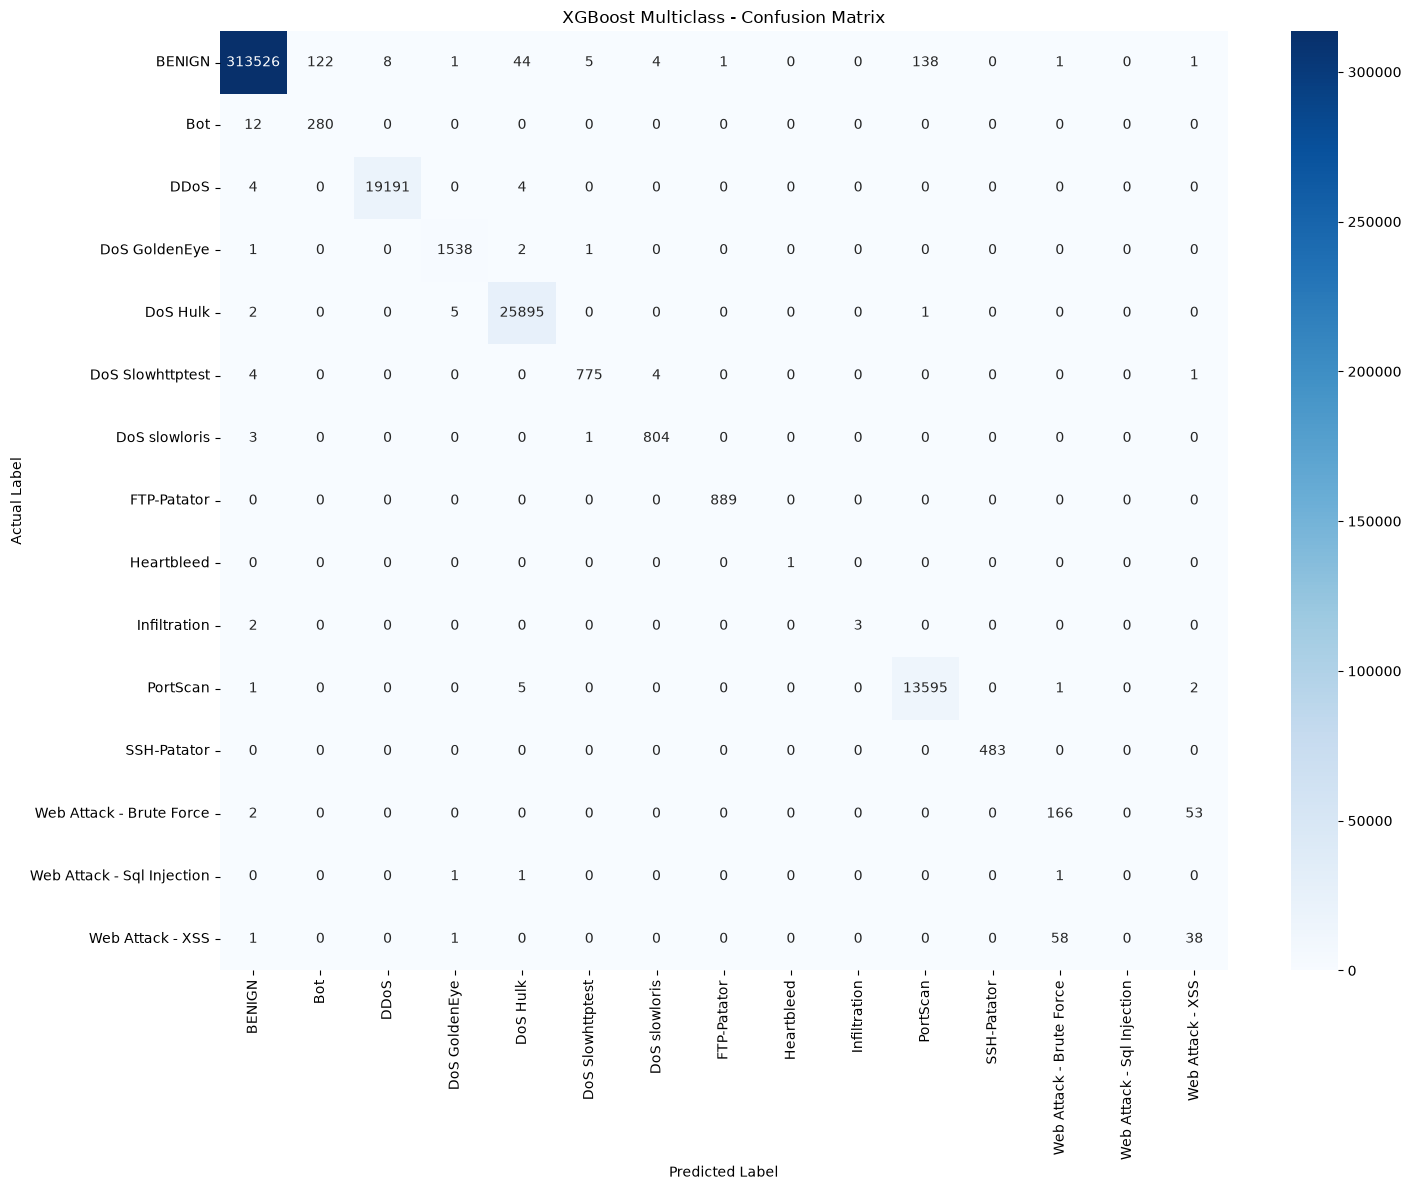

In [18]:
# Generate confusion matrix
cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=np.arange(len(label_encoder.classes_))
)

plt.figure(figsize=(15, 12))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("XGBoost Multiclass - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [19]:
# Create model directory
MODEL_DIR = Path("../models/xgboost")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save trained model
xgb_model.save_model(
    MODEL_DIR / "xgboost_multiclass.json"
)

# Save label encoder
joblib.dump(
    label_encoder,
    MODEL_DIR / "label_encoder.joblib"
)

# Save feature column order
with open(MODEL_DIR / "feature_columns.json", "w") as f:
    json.dump(feature_columns, f, indent=4)

# Save model metadata
metadata = {
    "model_name": "XGBoost Multiclass",
    "number_of_classes": len(label_encoder.classes_),
    "number_of_features": len(feature_columns),
    "best_iteration": int(xgb_model.best_iteration),
    "test_accuracy": float(test_accuracy),
    "test_macro_precision": float(test_precision),
    "test_macro_recall": float(test_recall),
    "test_macro_f1": float(test_f1)
}

with open(MODEL_DIR / "metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("MODEL SAVED SUCCESSFULLY!")

print("\nSaved files:")
for file in MODEL_DIR.iterdir():
    print(file.name, "-", round(file.stat().st_size / (1024**2), 2), "MB")

MODEL SAVED SUCCESSFULLY!

Saved files:
.gitkeep - 0.0 MB
feature_columns.json - 0.0 MB
label_encoder.joblib - 0.0 MB
metadata.json - 0.0 MB
xgboost_multiclass.json - 12.44 MB


In [20]:
# Load saved model
loaded_model = XGBClassifier()
loaded_model.load_model(MODEL_DIR / "xgboost_multiclass.json")

# Load saved encoder and feature columns
loaded_encoder = joblib.load(MODEL_DIR / "label_encoder.joblib")

with open(MODEL_DIR / "feature_columns.json", "r") as f:
    loaded_features = json.load(f)

# Test predictions on 100 records
original_predictions = xgb_model.predict(X_test[:100])
loaded_predictions = loaded_model.predict(X_test[:100])

print("MODEL VERIFICATION")
print("=" * 40)

print("Model loaded successfully:", True)
print("Encoder classes:", len(loaded_encoder.classes_))
print("Feature count:", len(loaded_features))

print(
    "Predictions match:",
    np.array_equal(original_predictions, loaded_predictions)
)

print("\nSample predictions:")
print(loaded_encoder.inverse_transform(loaded_predictions[:10]))

MODEL VERIFICATION
Model loaded successfully: True
Encoder classes: 15
Feature count: 65
Predictions match: True

Sample predictions:
['BENIGN' 'BENIGN' 'BENIGN' 'DoS Hulk' 'BENIGN' 'BENIGN' 'BENIGN'
 'DoS Hulk' 'BENIGN' 'BENIGN']
